# Phân tích kết quả LifeMate baseline v2

Notebook đọc **các file report đã chạy** trong `lifemate_baseline_v2/`. Các phần ASR, workflow và so sánh chỉ hiển thị khi report tương ứng đã có dữ liệu.

**Cách đọc điểm:** `score_proxy` là phép xấp xỉ do `baseline_v2/common.py` tính, không phải điểm leaderboard. `state_hash_match` là so sánh hash trạng thái cuối chính xác theo ToolEnv. `prompt_tokens_max` là độ dài context lớn nhất của **một lượt**; `prompt_tokens_total` cộng qua nhiều lượt.

In [23]:
from pathlib import Path
from collections import Counter
import ast
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_colwidth", 120)

# Có thể gán đường dẫn trực tiếp, ví dụ:
# REPORT_DIR = Path("/kaggle/working/lifemate_baseline_v2")
REPORT_DIR = None

def locate_report_dir(explicit=None):
    if explicit is not None:
        folder = Path(explicit).expanduser().resolve()
        if not (folder / "run_config.json").is_file():
            raise FileNotFoundError(f"Không thấy run_config.json trong {folder}")
        return folder
    candidates = []
    cwd = Path.cwd().resolve()
    for parent in (cwd, *cwd.parents):
        candidates.extend((parent, parent / "lifemate_baseline_v2"))
    candidates.append(Path("/kaggle/working/lifemate_baseline_v2"))
    for candidate in candidates:
        if (candidate / "run_config.json").is_file():
            return candidate
    raise FileNotFoundError("Không tìm thấy lifemate_baseline_v2; gán REPORT_DIR ở cell này.")

ROOT = locate_report_dir(REPORT_DIR)
config = json.loads((ROOT / "run_config.json").read_text(encoding="utf-8"))
print("Report:", ROOT)
print("Cấu hình:", {k: config.get(k) for k in
      ["mode", "sample_count", "llm_model", "llm_backend", "asr_model", "max_prompt_tokens", "max_new_tokens"]})

Report: /home/cyme/tnisl/zaloAI/lifemate_baseline_v2
Cấu hình: {'mode': 'workflow', 'sample_count': 30, 'llm_model': 'Qwen/Qwen3-4B-Instruct-2507', 'llm_backend': 'vllm', 'asr_model': 'vinai/PhoWhisper-medium', 'max_prompt_tokens': 11500, 'max_new_tokens': 512}


In [24]:
def read_jsonl(path):
    if not path.is_file() or path.stat().st_size == 0:
        return []
    with path.open(encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

def read_json(path):
    return json.loads(path.read_text(encoding="utf-8")) if path.is_file() and path.stat().st_size else None

def decode_cell(value):
    if not isinstance(value, str):
        return value
    s = value.strip()
    if not s:
        return value
    try:
        return json.loads(s)
    except (json.JSONDecodeError, TypeError):
        try:
            return ast.literal_eval(s)
        except (ValueError, SyntaxError):
            return value

JSON_COLS = [
    "missing_tool_names", "extra_tool_names", "error_flags",
    "gold_tool_calls", "tool_calls", "prompt_tokens_each", "grounding_prompt_tokens_each",
]

def read_cases(path):
    if not path.is_file() or path.stat().st_size == 0:
        return pd.DataFrame()
    df = pd.read_csv(path, keep_default_na=False)
    for col in JSON_COLS:
        if col in df:
            df[col] = df[col].map(decode_cell)
    for col in ("state_hash_match", "context_trimmed"):
        if col in df:
            df[col] = df[col].map(lambda x: str(x).lower() == "true")
    numeric = [
        "score_proxy", "gold_tool_count", "tool_count", "matched_calls_proxy",
        "decisions", "tool_iterations", "repair_attempts",
        "invalid_schema_proposals", "parse_errors", "duplicate_proposals",
        "prompt_tokens_total", "prompt_tokens_max", "generation_tokens_total", "grounding_rejections", "semantic_rejections",
        "grounding_reviews", "grounding_generation_tokens_total", "grounding_llm_latency_s",
        "unverified_arguments", "tool_failures", "no_progress_events",
        "llm_latency_s", "agent_latency_s", "asr_latency_s",
        "pipeline_latency_s", "asr_wer", "asr_cer", "wer", "cer",
        "duration_s", "word_errors", "ref_words",
    ]
    for col in numeric:
        if col in df:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    return df

def load_mode(name):
    folder = ROOT / name
    return {
        "name": name,
        "summary": read_json(folder / "summary.json"),
        "cases": read_cases(folder / "cases.csv"),
        "predictions": read_jsonl(folder / "predictions.jsonl"),
        "traces": read_jsonl(folder / "traces.jsonl"),
    }

runs = {name: load_mode(name) for name in ("asr", "workflow_gold", "baseline_asr")}
status = pd.DataFrame([
    {"experiment": name, "cases": len(run["cases"]),
     "predictions": len(run["predictions"]), "traces": len(run["traces"]),
     "summary": run["summary"] is not None}
    for name, run in runs.items()
])
display(status)
for name, run in runs.items():
    if run["summary"] is None:
        print(f"{name}: chưa có summary; các phần cần dữ liệu này sẽ được bỏ qua.")
workflow = runs["workflow_gold"]["cases"]
baseline = runs["baseline_asr"]["cases"]
asr = runs["asr"]["cases"]

,experiment,cases,predictions,traces,summary
0,asr,0,0,0,False
1,workflow_gold,30,30,30,True
2,baseline_asr,0,0,0,False


asr: chưa có summary; các phần cần dữ liệu này sẽ được bỏ qua.
baseline_asr: chưa có summary; các phần cần dữ liệu này sẽ được bỏ qua.


## 1. Tổng quan workflow

`state_hash_match=False` có nghĩa trạng thái cuối khác nhãn; các case đó nhận `score_proxy=0`. Một case hash đúng vẫn có thể sai tool hoặc arguments. Dùng bảng và biểu đồ dưới đây để phân biệt hai lỗi.

,Chỉ số,Giá trị
0,Số mẫu,30
1,Điểm proxy trung bình,22.78%
2,Proxy > 0,8
3,Proxy = 1,5
4,Hash đúng,40.00% (12/30)
5,Số quyết định trung bình,3.17
6,Số tool call trung bình,1.07
7,Context lớn nhất / p95,5633 / 5522 tokens
8,Agent latency trung bình / p95,47.57 / 96.07 s
9,Agent latency > 30 s,22


Ghi chú: workflow chỉ đo thời gian agent; không gồm ASR.


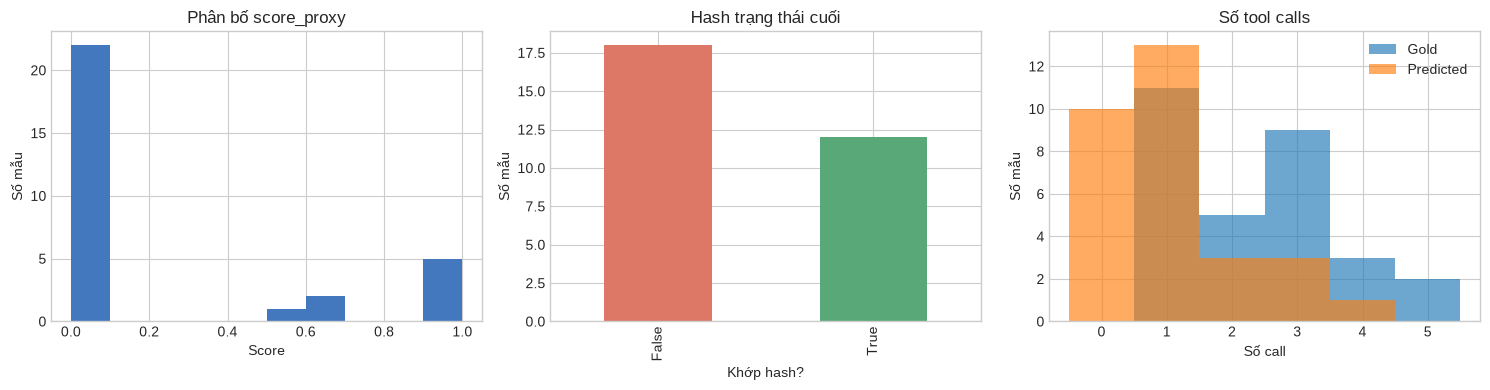

In [25]:
if workflow.empty:
    display(Markdown("Chưa có workflow_gold/cases.csv."))
else:
    wf = runs["workflow_gold"]["summary"] or {}
    overview = pd.DataFrame([
        ("Số mẫu", len(workflow)),
        ("Điểm proxy trung bình", f"{workflow.score_proxy.mean():.2%}"),
        ("Proxy > 0", int((workflow.score_proxy > 0).sum())),
        ("Proxy = 1", int((workflow.score_proxy == 1).sum())),
        ("Hash đúng", f"{workflow.state_hash_match.mean():.2%} ({int(workflow.state_hash_match.sum())}/{len(workflow)})"),
        ("Số quyết định trung bình", f"{workflow.decisions.mean():.2f}"),
        ("Số tool call trung bình", f"{workflow.tool_count.mean():.2f}"),
        ("Context lớn nhất / p95", f"{workflow.prompt_tokens_max.max():.0f} / {workflow.prompt_tokens_max.quantile(.95):.0f} tokens"),
        ("Agent latency trung bình / p95", f"{workflow.agent_latency_s.mean():.2f} / {workflow.agent_latency_s.quantile(.95):.2f} s"),
        ("Agent latency > 30 s", int((workflow.agent_latency_s > 30).sum())),
    ], columns=["Chỉ số", "Giá trị"])
    display(overview)
    print("Ghi chú: workflow chỉ đo thời gian agent; không gồm ASR.")
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    workflow.score_proxy.plot.hist(bins=np.linspace(0, 1, 11), ax=ax[0], color="#4378bf")
    ax[0].set(title="Phân bố score_proxy", xlabel="Score", ylabel="Số mẫu")
    workflow.groupby("state_hash_match").size().reindex([False, True], fill_value=0).plot.bar(
        ax=ax[1], color=["#dd7766", "#58a878"])
    ax[1].set(title="Hash trạng thái cuối", xlabel="Khớp hash?", ylabel="Số mẫu")
    workflow[["gold_tool_count", "tool_count"]].rename(
        columns={"gold_tool_count": "Gold", "tool_count": "Predicted"}).plot.hist(
        bins=np.arange(-0.5, max(workflow[["gold_tool_count", "tool_count"]].max()) + 1.5),
        alpha=.65, ax=ax[2])
    ax[2].set(title="Số tool calls", xlabel="Số call", ylabel="Số mẫu")
    plt.tight_layout()
    plt.show()

## 2. Nguyên nhân lỗi và điểm dừng

Một mẫu có thể mang nhiều `error_flags`, vì thế tổng cột lỗi có thể lớn hơn số mẫu. `stop_reason` là lý do agent ngừng, không nhất thiết là nguyên nhân duy nhất của điểm thấp.

,error_flag,cases
1,missing_tool,21
0,state_hash_mismatch,18
2,issue_no_progress,12
3,validation_no_progress,10
4,extra_tool,5
5,argument_mismatch,3


,stop_reason,cases
0,issue_no_progress,12
1,validation_no_progress,10
2,done,7
3,ask_missing_info,1


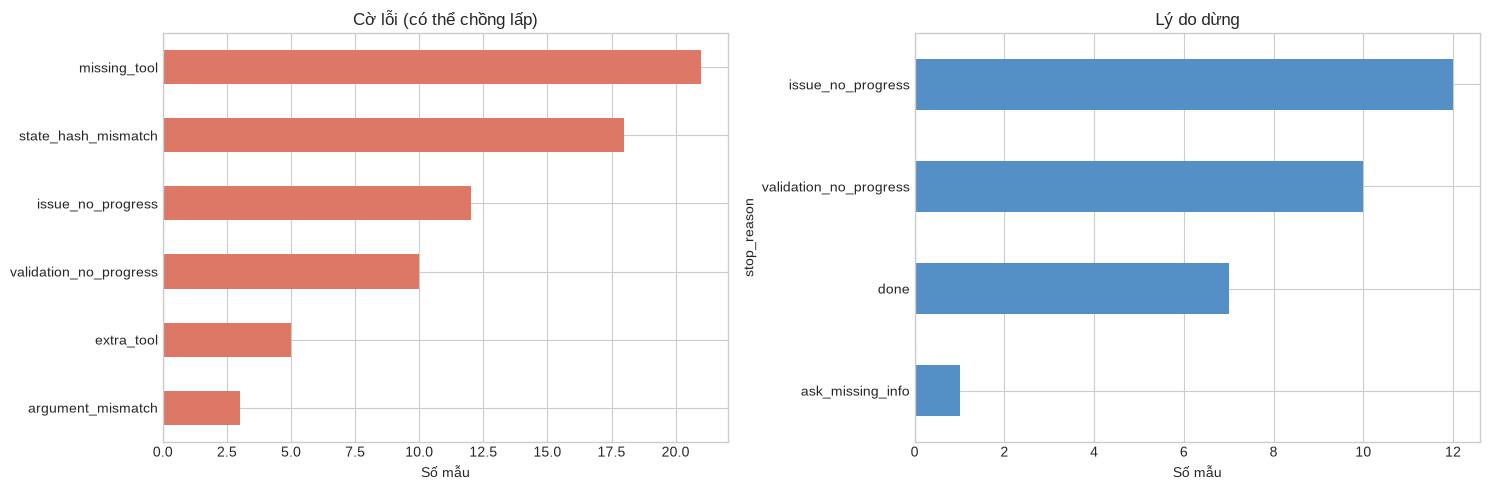

state_hash_match,hash sai,hash đúng,All
stop_reason,,,
ask_missing_info,1,0,1
done,1,6,7
issue_no_progress,9,3,12
validation_no_progress,7,3,10
All,18,12,30


In [26]:
if not workflow.empty:
    flags = Counter(flag for xs in workflow.error_flags for flag in xs)
    reasons = workflow.stop_reason.value_counts()
    display(pd.DataFrame(flags.items(), columns=["error_flag", "cases"]).sort_values("cases", ascending=False))
    display(reasons.rename_axis("stop_reason").reset_index(name="cases"))
    fig, ax = plt.subplots(1, 2, figsize=(15, 5))
    pd.Series(flags).sort_values().plot.barh(ax=ax[0], color="#dd7766")
    ax[0].set(title="Cờ lỗi (có thể chồng lấp)", xlabel="Số mẫu")
    reasons.sort_values().plot.barh(ax=ax[1], color="#548fc6")
    ax[1].set(title="Lý do dừng", xlabel="Số mẫu")
    plt.tight_layout()
    plt.show()
    display(pd.crosstab(workflow.stop_reason, workflow.state_hash_match,
                        margins=True).rename(columns={False: "hash sai", True: "hash đúng"}))

## 3. Context, số lần lặp và thời gian

`prompt_tokens_max` là context lớn nhất của cả lượt lập kế hoạch hoặc lượt Qwen xác nhận grounding. `prompt_tokens_total` cộng token của cả hai loại lượt. `grounding_reviews` là số lần Qwen xác nhận. `decisions` gồm cả lần sửa JSON/schema; `tool_count` chỉ đếm call được ToolEnv ghi nhận.

,count,mean,std,min,50%,90%,95%,max
prompt_tokens_max,30.0,4077.67,898.79,2486.00,3851.50,5425.90,5522.20,5633.0
prompt_tokens_total,30.0,20352.13,10722.53,6365.00,19216.50,32136.00,36126.60,58701.0
generation_tokens_total,30.0,413.70,235.30,78.00,370.00,760.70,877.40,981.0
grounding_rejections,30.0,0.23,0.43,0.00,0.00,1.00,1.00,1.0
semantic_rejections,30.0,0.03,0.18,0.00,0.00,0.00,0.00,1.0
grounding_reviews,30.0,0.00,0.00,0.00,0.00,0.00,0.00,0.0
grounding_generation_tokens_total,30.0,0.00,0.00,0.00,0.00,0.00,0.00,0.0
grounding_llm_latency_s,30.0,0.00,0.00,0.00,0.00,0.00,0.00,0.0
unverified_arguments,30.0,0.97,1.22,0.00,0.50,2.10,3.55,4.0
tool_failures,30.0,0.07,0.25,0.00,0.00,0.00,0.55,1.0


,cases,mean_score,hash_accuracy
agent_over_30s,,,
False,8,0.500,0.625
True,22,0.129,0.318


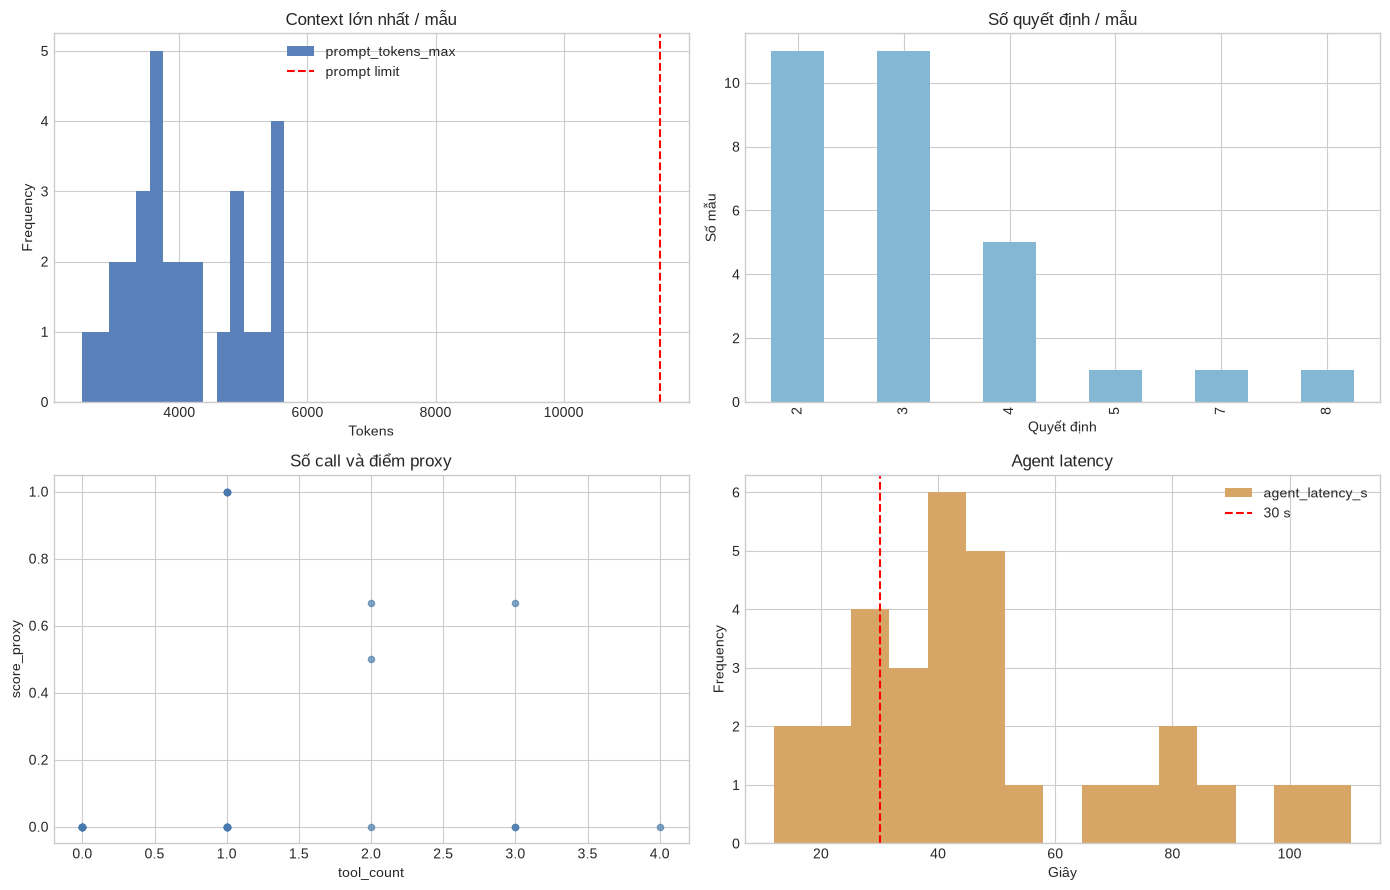

In [27]:
if not workflow.empty:
    cols = ["prompt_tokens_max", "prompt_tokens_total", "generation_tokens_total", "grounding_rejections", "semantic_rejections",
        "grounding_reviews", "grounding_generation_tokens_total", "grounding_llm_latency_s",
        "unverified_arguments", "tool_failures", "no_progress_events",
            "decisions", "tool_count", "repair_attempts", "agent_latency_s"]
    display(workflow[cols].describe(percentiles=[.5, .9, .95]).T.round(2))
    display(workflow.assign(agent_over_30s=workflow.agent_latency_s > 30).groupby(
        "agent_over_30s", dropna=False).agg(
        cases=("id", "count"), mean_score=("score_proxy", "mean"),
        hash_accuracy=("state_hash_match", "mean")).round(3))
    fig, ax = plt.subplots(2, 2, figsize=(14, 9))
    workflow.prompt_tokens_max.plot.hist(bins=15, ax=ax[0, 0], color="#5a81ba")
    ax[0, 0].axvline(config.get("max_prompt_tokens", 11500), color="red", ls="--", label="prompt limit")
    ax[0, 0].legend()
    ax[0, 0].set(title="Context lớn nhất / mẫu", xlabel="Tokens")
    workflow.decisions.value_counts().sort_index().plot.bar(ax=ax[0, 1], color="#84b7d4")
    ax[0, 1].set(title="Số quyết định / mẫu", xlabel="Quyết định", ylabel="Số mẫu")
    workflow.plot.scatter(x="tool_count", y="score_proxy", ax=ax[1, 0], alpha=.65, color="#4879ae")
    ax[1, 0].set(title="Số call và điểm proxy")
    workflow.agent_latency_s.plot.hist(bins=15, ax=ax[1, 1], color="#d7a667")
    ax[1, 1].axvline(30, color="red", ls="--", label="30 s")
    ax[1, 1].legend()
    ax[1, 1].set(title="Agent latency", xlabel="Giây")
    plt.tight_layout()
    plt.show()

,id,decision,prompt_tokens,generation_tokens,llm_latency_s,grounding_prompt_tokens,grounding_approved,grounding_stage,reject_reason,auto_corrected_ask,action_type,action_tool,event_error,no_new_information
0,train_0063,1,4169,77,16.828158,None,None,None,None,False,call,sms.send,None,False
1,train_0063,2,4296,20,2.233148,None,None,None,None,False,done,NaN,None,False
2,train_0066,1,2881,71,8.627516,None,None,None,None,False,call,reminders.create,None,False
3,train_0066,2,3072,20,2.266612,None,None,None,None,False,done,NaN,None,False
4,train_0075,1,3581,102,12.887996,None,None,None,None,False,call,smart_home.get_status,"{'error': 'selector_issue', 'stage': 'argument_selection', 'tool': 'smart_home.get_status', 'issue': {'type': 'unsup...",False
5,train_0075,2,3685,50,5.085870,None,None,None,None,False,call,smart_home.get_status,"{'error': 'selector_issue', 'stage': 'value_selection', 'tool': 'smart_home.get_status', 'issue': {'type': 'missing_...",False
6,train_0075,3,3689,45,4.521318,None,None,None,None,False,call,smart_home.get_status,"{'error': 'selector_issue', 'stage': 'value_selection', 'tool': 'smart_home.get_status', 'issue': {'type': 'missing_...",True
7,train_0080,1,4285,94,13.192701,None,None,None,None,False,call,bill_payment.list_bills,None,False
8,train_0080,2,4526,49,5.390399,None,None,None,None,False,call,bill_payment.list_bills,"{'error': 'selector_issue', 'stage': 'value_selection', 'tool': 'bill_payment.list_bills', 'issue': {'type': 'missin...",False
9,train_0080,3,4609,79,8.226298,None,None,None,None,False,call,bill_payment.list_bills,"{'error': 'selector_issue', 'stage': 'value_selection', 'tool': 'bill_payment.list_bills', 'issue': {'type': 'missin...",True


,mean,min,max,count
decision,,,,
1,3879.7,2268,5555,30
2,4000.2,2408,5633,30
3,3996.3,2486,5550,19
4,4294.5,3237,5587,8
5,4591.7,3939,5003,3
6,4516.5,3970,5063,2
7,4525.5,3961,5090,2
8,5164.0,5164,5164,1


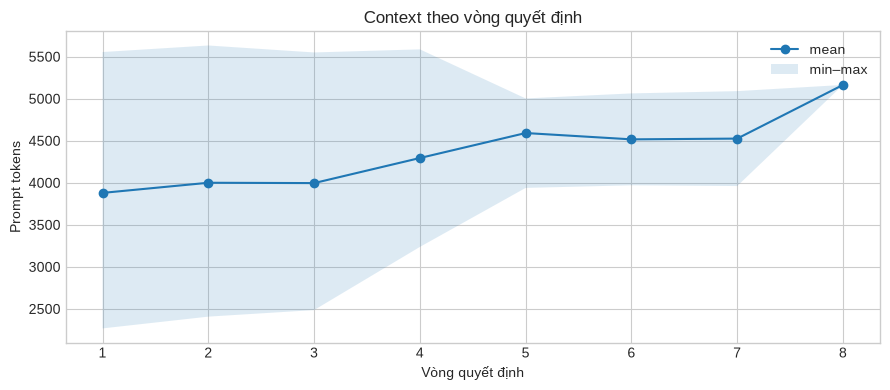

In [28]:
if runs["workflow_gold"]["traces"]:
    turns = pd.DataFrame([
        {"id": item["id"], "decision": event.get("decision"),
         "prompt_tokens": event.get("prompt_tokens"),
         "generation_tokens": event.get("generation_tokens"),
         "llm_latency_s": event.get("llm_latency_s"),
         "grounding_prompt_tokens": ((event.get("grounding") or {}).get("usage") or {}).get("prompt_tokens"),
         "grounding_approved": (event.get("grounding") or {}).get("ok"),
         "grounding_stage": (event.get("grounding") or {}).get("stage"),
         "reject_reason": ((event.get("grounding") or {}).get("review") or {}).get("reject_reason"),
         "auto_corrected_ask": bool(event.get("auto_corrected_ask")),
         "action_type": (event.get("action") or {}).get("type"),
         "action_tool": (event.get("action") or {}).get("name",
                         (event.get("action") or {}).get("tool_name")),
         "event_error": event.get("error"),
         "no_new_information": event.get("no_new_information", False)}
        for item in runs["workflow_gold"]["traces"] for event in item.get("trace", [])
    ])
    display(turns.head(10))
    curve = turns.groupby("decision").prompt_tokens.agg(["mean", "min", "max", "count"])
    display(curve.round(1))
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(curve.index, curve["mean"], marker="o", label="mean")
    ax.fill_between(curve.index, curve["min"], curve["max"], alpha=.15, label="min–max")
    ax.set(title="Context theo vòng quyết định", xlabel="Vòng quyết định", ylabel="Prompt tokens")
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print("Chưa có traces để phân tích từng quyết định.")

## 4. Tool thiếu, thừa và các case cần xem

Các cột tool trong `cases.csv` đã được đối chiếu với nhãn train. Bảng dưới đây ưu tiên mẫu điểm 0 và các cờ lỗi phổ biến. Hàm `show_case` in toàn bộ tool calls và trace để kiểm tra từng quyết định của model.

,tool,gold,predicted,missing,extra
6,bill_payment.pay,6,0,6,0
13,contacts.search,3,0,3,0
5,bill_payment.list_bills,5,4,2,1
45,sys.ask_missing_info,2,1,2,1
37,reminders.create,3,1,2,0
40,smart_home.get_status,2,0,2,0
41,smart_home.light_set,2,0,2,0
42,sms.send,3,1,2,0
3,banking.list_beneficiaries,1,1,1,1
19,food_delivery.list_restaurants,1,1,1,1


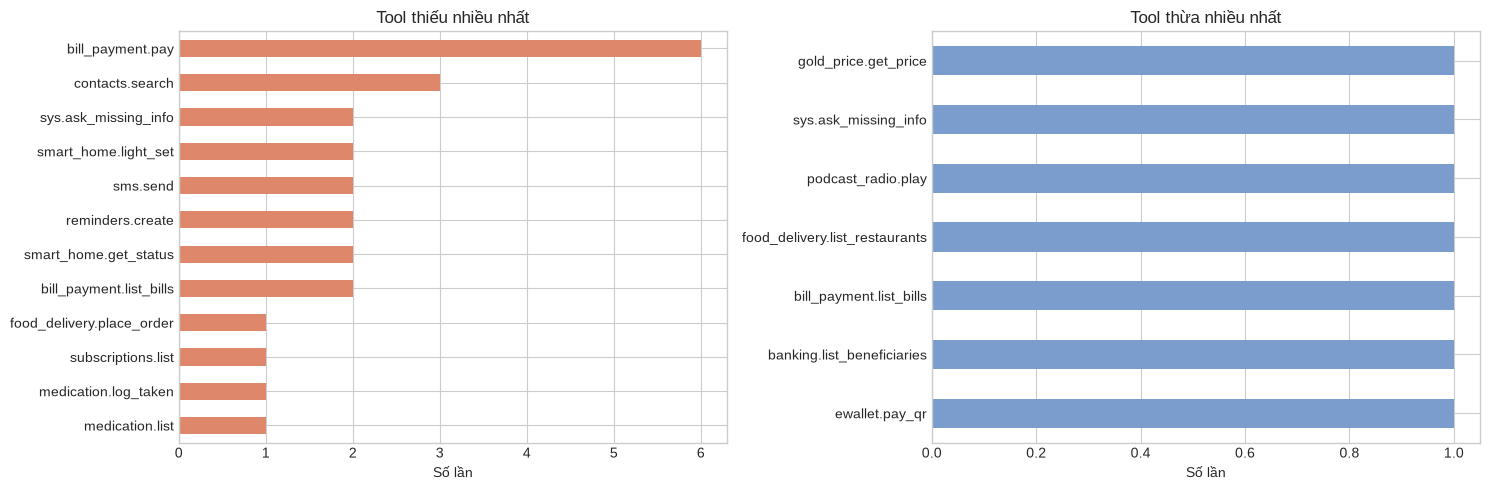

,id,reference,score_proxy,state_hash_match,gold_tool_count,tool_count,stop_reason,error_flags,missing_tool_names,extra_tool_names
2,train_0075,"Bật đèn phòng khách thôi, mà để mờ 50 phần trăm, quạt thì đừng bật, với bật điều hoà phòng khách 26 độ.",0.0,False,3,0,issue_no_progress,"[state_hash_mismatch, missing_tool, issue_no_progress]","[smart_home.get_status, smart_home.light_set, smart_home.climate_set]",[]
3,train_0080,"Trả giúp tôi tất cả hoá đơn sắp đến hạn trong năm ngày tới bằng ngân hàng, riêng hoá đơn nào hơn 500 nghìn thì khoan...",0.0,False,3,1,issue_no_progress,"[state_hash_mismatch, missing_tool, issue_no_progress]","[bill_payment.pay, bill_payment.pay]",[]
4,train_0203,"Nếu ví đủ thì đóng tiền mạng bằng ví và nhắn SMS Hương là đã đóng, còn ví thiếu thì trả bằng ngân hàng và nhắc tôi n...",0.0,False,5,2,validation_no_progress,"[state_hash_mismatch, missing_tool, validation_no_progress]","[bill_payment.pay, contacts.search, sms.send]",[]
5,train_0216,"Trả tiền truyền hình bằng ví cho chị, ví không đủ thì lấy tài khoản ngân hàng nha.",0.0,False,3,3,issue_no_progress,"[state_hash_mismatch, missing_tool, extra_tool, issue_no_progress]","[bill_payment.list_bills, bill_payment.pay]","[ewallet.pay_qr, banking.list_beneficiaries]"
6,train_0236,"Nếu ví đủ thì trả tiền truyền hình bằng ví và nhắn SMS sếp Dũng là đã đóng, còn thiếu thì trả qua ngân hàng và nhắc ...",0.0,False,5,1,validation_no_progress,"[state_hash_mismatch, missing_tool, validation_no_progress]","[bill_payment.list_bills, bill_payment.pay, contacts.search, sms.send]",[]
7,train_0255,"Vàng SJC bán ra mà trên 122 triệu thì 9 giờ sáng mai nhắc tôi đi bán vàng, chưa tới thì chuyển cho Lê Minh 2 triệu t...",0.0,False,4,0,issue_no_progress,"[state_hash_mismatch, missing_tool, issue_no_progress]","[gold_price.get_price, banking.get_balance, banking.list_beneficiaries, banking.transfer]",[]
8,train_0313,"Trả tiền nước bằng ví điện tử đi, ví không đủ thì lấy tài khoản ngân hàng trả nhé.",0.0,False,3,4,issue_no_progress,"[state_hash_mismatch, missing_tool, extra_tool, issue_no_progress]",[bill_payment.pay],"[bill_payment.list_bills, food_delivery.list_restaurants]"
10,train_0476,Hôm nay nhà mình dùng hết bao nhiêu điện rồi? Tiện thì cài cho anh bảy giờ tối hằng ngày tự bật đèn trần phòng khách...,0.0,False,4,1,issue_no_progress,"[state_hash_mismatch, missing_tool, issue_no_progress]","[smart_home.get_status, home_automation.create_rule, smart_home.light_set]",[]
12,train_0508,"Huỷ giúp anh cái gói Video Gia Đình đi em, rồi soạn sẵn một thư nháp gửi vợ anh, báo là gói đó sẽ không gia hạn nữa....",0.0,False,4,3,done,"[state_hash_mismatch, missing_tool]",[contacts.search],[]
13,train_0538,"Xem giúp tôi mấy cái cảnh báo ở cửa sổ phòng làm việc, cái nào mới nhất thì chép nguyên nội dung vào một ghi chú tên...",0.0,False,2,1,validation_no_progress,"[state_hash_mismatch, missing_tool, validation_no_progress]",[notes.create],[]


In [29]:
if not workflow.empty:
    missing = Counter(name for xs in workflow.missing_tool_names for name in xs)
    extra = Counter(name for xs in workflow.extra_tool_names for name in xs)
    gold = Counter(call["name"] for calls in workflow.gold_tool_calls for call in calls)
    predicted = Counter(call["name"] for calls in workflow.tool_calls for call in calls)
    names = sorted(set(gold) | set(predicted) | set(missing) | set(extra))
    tool_table = pd.DataFrame([
        {"tool": name, "gold": gold[name], "predicted": predicted[name],
         "missing": missing[name], "extra": extra[name]}
        for name in names
    ]).sort_values(["missing", "extra"], ascending=False)
    display(tool_table.head(25))
    fig, ax = plt.subplots(1, 2, figsize=(15, 5))
    pd.Series(missing).sort_values().tail(12).plot.barh(ax=ax[0], color="#df876b")
    ax[0].set(title="Tool thiếu nhiều nhất", xlabel="Số lần")
    pd.Series(extra).sort_values().tail(12).plot.barh(ax=ax[1], color="#7a9dcd")
    ax[1].set(title="Tool thừa nhiều nhất", xlabel="Số lần")
    plt.tight_layout()
    plt.show()
    view_cols = ["id", "reference", "score_proxy", "state_hash_match",
                 "gold_tool_count", "tool_count", "stop_reason", "error_flags",
                 "missing_tool_names", "extra_tool_names"]
    display(workflow.sort_values(["score_proxy", "state_hash_match", "id"])[view_cols].head(20))

In [35]:
def show_case(sample_id, mode="workflow_gold"):
    run = runs[mode]
    df = run["cases"]
    if df.empty or sample_id not in set(df.id):
        print(f"Không có {sample_id} trong {mode}.")
        return
    row = df.loc[df.id == sample_id].iloc[0]
    for col in ["id", "reference", "transcript", "score_proxy", "state_hash_match",
                "gold_state_hash", "state_hash", "stop_reason", "error_flags",
                "gold_tool_calls", "tool_calls"]:
        if col in row.index:
            value = row[col]
            print(f"\n{col}:")
            print(json.dumps(value, ensure_ascii=False, indent=2, default=str)
                  if isinstance(value, (dict, list)) else value)
    found = next((x for x in run["traces"] if x["id"] == sample_id), None)
    if found:
        print("\nTrace:")
        for e in found.get("trace", []):
            print(json.dumps({
                "decision": e.get("decision"),
                "action": e.get("action"),
                "validation": e.get("validation"),
                "missing_fields": e.get("missing_fields"),
                "no_new_information": e.get("no_new_information"),
                "error": e.get("error"),
                "tool_result": e.get("tool_result"),
            }, ensure_ascii=False, indent=2, default=str))

if not workflow.empty:
    example_id = workflow.sort_values(["score_proxy", "id"]).iloc[1].id
    # example_id = "train_1715"
    print("Ví dụ case:", example_id, "(đổi ID bên dưới để xem case khác)")
    show_case(example_id)

Ví dụ case: train_0080 (đổi ID bên dưới để xem case khác)

id:
train_0080

reference:
Trả giúp tôi tất cả hoá đơn sắp đến hạn trong năm ngày tới bằng ngân hàng, riêng hoá đơn nào hơn 500 nghìn thì khoan trả, để đó đã.

transcript:
Trả giúp tôi tất cả hoá đơn sắp đến hạn trong năm ngày tới bằng ngân hàng, riêng hoá đơn nào hơn 500 nghìn thì khoan trả, để đó đã.

score_proxy:
0.0

state_hash_match:
False

gold_state_hash:
42363426e1cd503eb28e9c3ecf2734389159116437fcb7731a2ec5e963a6715b

state_hash:
d131436ef8344b2a7239cf7394ed52af24e123576807430de9e7ed31d08f8c7d

stop_reason:
issue_no_progress

error_flags:
[
  "state_hash_mismatch",
  "missing_tool",
  "issue_no_progress"
]

gold_tool_calls:
[
  {
    "name": "bill_payment.list_bills",
    "arguments": {}
  },
  {
    "name": "bill_payment.pay",
    "arguments": {
      "bill_id": "bill_02",
      "source": "bank"
    }
  },
  {
    "name": "bill_payment.pay",
    "arguments": {
      "bill_id": "bill_03",
      "source": "bank"
    }
 

## 5. ASR và baseline khi có kết quả

ASR chỉ có thống kê WER/CER nếu `asr/cases.csv` được tạo xong. File `asr/predictions.jsonl` rỗng thường nghĩa là run trước đã dừng trước khi ghi được mẫu ASR nào. So sánh workflow với baseline chỉ hiển thị khi cả hai có `cases.csv`.

In [31]:
if asr.empty:
    print("ASR: chưa có asr/cases.csv; hiện không thể tính WER/CER từ report này.")
    print("Số ASR predictions:", len(runs["asr"]["predictions"]))
else:
    summary = runs["asr"]["summary"] or {}
    display(pd.DataFrame([
        ("Số mẫu", len(asr)),
        ("Corpus WER", summary.get("corpus_wer")),
        ("Corpus CER", summary.get("corpus_cer")),
        ("WER trung bình theo mẫu", asr.wer.mean()),
        ("Transcript đúng hoàn toàn", int((asr.word_errors == 0).sum())),
        ("ASR latency p95 (s)", asr.asr_latency_s.quantile(.95)),
    ], columns=["Chỉ số", "Giá trị"]))
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    asr.wer.plot.hist(bins=15, ax=ax[0], color="#668fbd")
    ax[0].set(title="WER theo mẫu", xlabel="WER")
    asr.asr_latency_s.plot.hist(bins=15, ax=ax[1], color="#d5a069")
    ax[1].set(title="ASR latency", xlabel="Giây")
    plt.tight_layout()
    plt.show()
    display(asr.sort_values("wer", ascending=False)[
        ["id", "reference", "transcript", "wer", "cer", "word_errors"]].head(15))

ASR: chưa có asr/cases.csv; hiện không thể tính WER/CER từ report này.
Số ASR predictions: 0


In [32]:
if baseline.empty:
    print("Chưa có baseline_asr/cases.csv; chưa thể đo ảnh hưởng ASR lên workflow.")
else:
    modes = [("workflow_gold", workflow), ("baseline_asr", baseline)]
    compare = pd.DataFrame([
        {"experiment": name, "samples": len(df),
         "mean_score_proxy": df.score_proxy.mean(),
         "perfect_proxy": int((df.score_proxy == 1).sum()),
         "hash_accuracy": df.state_hash_match.mean(),
         "mean_calls": df.tool_count.mean(),
         "mean_decisions": df.decisions.mean(),
         "agent_latency_p95_s": df.agent_latency_s.quantile(.95),
         "pipeline_over_30s": int((df.pipeline_latency_s > 30).sum())
             if "pipeline_latency_s" in df else np.nan}
        for name, df in modes if not df.empty
    ])
    display(compare.round(3))
    if not workflow.empty:
        paired = workflow[["id", "score_proxy", "state_hash_match", "tool_calls"]].merge(
            baseline[["id", "score_proxy", "state_hash_match", "tool_calls",
                      "asr_wer", "pipeline_latency_s"]],
            on="id", suffixes=("_workflow", "_baseline"))
        paired["delta_score"] = paired.score_proxy_baseline - paired.score_proxy_workflow
        paired["category"] = np.select(
            [
                (paired.score_proxy_workflow == 1) & (paired.score_proxy_baseline == 1),
                (paired.score_proxy_workflow == 1) & (paired.score_proxy_baseline < 1),
                (paired.score_proxy_workflow < 1) & (paired.score_proxy_baseline == 1),
            ],
            ["both_correct", "asr_sensitive", "asr_helped"],
            default="shared_failure",
        )
        display(paired.category.value_counts().rename_axis("category").reset_index(name="cases"))
        display(paired.sort_values("delta_score")[[
            "id", "score_proxy_workflow", "score_proxy_baseline", "delta_score",
            "asr_wer", "pipeline_latency_s", "category"]].head(15))
        print("asr_sensitive là tương quan; chưa chứng minh lỗi ASR là nguyên nhân trực tiếp.")

Chưa có baseline_asr/cases.csv; chưa thể đo ảnh hưởng ASR lên workflow.


## 6. Cách đọc kết quả hiện tại

- Ưu tiên xem các mẫu `state_hash_match=False`: trạng thái cuối sai thì `score_proxy` bằng 0.
- Kiểm tra `missing_tool_names` và `extra_tool_names` để biết agent bỏ sót hoặc gọi dư bước nào.
- Với `invalid_ask` và `duplicate_no_progress`, dùng `show_case(id)` để đọc action và tool response theo thứ tự.
- Khi có kết quả `baseline_asr`, đọc bảng ghép theo ID để biết mẫu nào nhạy với transcript ASR.
- Thống kê tốc độ của `workflow_gold` chỉ có thời gian agent. Giới hạn 30 giây của pipeline phải xem ở `baseline_asr`.

## 7. Kiểm tra mới của v2

Các cột này đếm đề xuất bị chặn trước khi gọi tool, argument chưa được xác minh tự động và tool trả kết quả thất bại. Số lần bị chặn cao có thể bảo vệ trạng thái nhưng cũng có thể làm thiếu tool; đọc trace trước khi kết luận.

,mode,metric,total,mean_per_sample,samples_positive
0,workflow_gold,grounding_rejections,7,0.23,7
1,workflow_gold,semantic_rejections,1,0.03,1
2,workflow_gold,unverified_arguments,29,0.97,15
3,workflow_gold,tool_failures,2,0.07,2
4,workflow_gold,no_progress_events,0,0.00,0


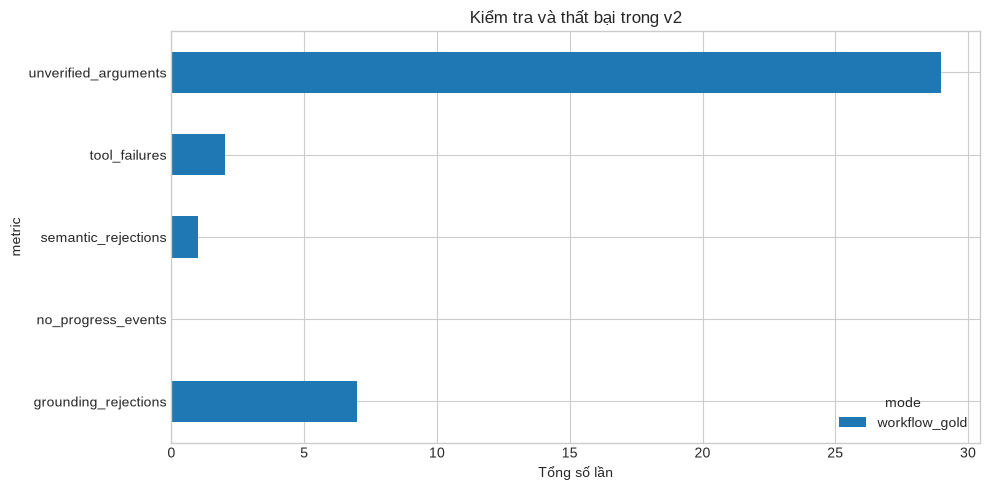

,id,score_proxy,grounding_rejections,semantic_rejections,tool_failures,stop_reason
5,train_0216,0.000000,1,0,1,issue_no_progress
10,train_0476,0.000000,1,0,0,issue_no_progress
13,train_0538,0.000000,1,0,0,validation_no_progress
14,train_0618,0.000000,1,0,0,issue_no_progress
15,train_0953,0.666667,1,0,0,validation_no_progress
26,train_1653,0.000000,1,0,0,issue_no_progress
27,train_1703,0.000000,1,0,0,issue_no_progress
17,train_1155,0.000000,0,0,1,issue_no_progress


In [33]:
v2_cols = ["grounding_rejections", "semantic_rejections", "unverified_arguments", "tool_failures", "no_progress_events"]
rows = []
for mode, df in (("workflow_gold", workflow), ("baseline_asr", baseline)):
    if df.empty:
        continue
    for col in v2_cols:
        if col in df:
            rows.append({"mode": mode, "metric": col, "total": df[col].sum(),
                         "mean_per_sample": df[col].mean(),
                         "samples_positive": int((df[col] > 0).sum())})
if rows:
    v2_metrics = pd.DataFrame(rows)
    display(v2_metrics.round(2))
    ax = v2_metrics.pivot(index="metric", columns="mode", values="total").plot.barh(
        figsize=(10, 5), title="Kiểm tra và thất bại trong v2")
    ax.set_xlabel("Tổng số lần")
    plt.tight_layout()
    plt.show()
    if not workflow.empty:
        candidates = workflow[(workflow.grounding_rejections > 0) | (workflow.tool_failures > 0)]
        display(candidates[["id", "score_proxy", "grounding_rejections",
                            "semantic_rejections", "tool_failures", "stop_reason"]]
                .sort_values(["grounding_rejections", "tool_failures"], ascending=False).head(20))
else:
    print("Chưa có các cột v2 trong report này.")

## 8. So sánh v1 và v2 trên cùng ID

Chỉ so sánh các ID xuất hiện ở cả hai report. Đảm bảo model, seed, limit và chế độ chạy tương ứng khi diễn giải chênh lệch.

In [34]:
old_root = ROOT.parent / "lifemate_baseline"
comparison_rows = []
for mode, v2_df in (("workflow_gold", workflow), ("baseline_asr", baseline)):
    v1_df = read_cases(old_root / mode / "cases.csv")
    if v1_df.empty or v2_df.empty:
        continue
    pair = v1_df[["id", "score_proxy", "state_hash_match"]].merge(
        v2_df[["id", "score_proxy", "state_hash_match"]],
        on="id", suffixes=("_v1", "_v2"))
    if pair.empty:
        continue
    comparison_rows.append({
        "mode": mode, "shared_ids": len(pair),
        "mean_proxy_v1": pair.score_proxy_v1.mean(),
        "mean_proxy_v2": pair.score_proxy_v2.mean(),
        "hash_accuracy_v1": pair.state_hash_match_v1.mean(),
        "hash_accuracy_v2": pair.state_hash_match_v2.mean(),
        "v2_improved": int((pair.score_proxy_v2 > pair.score_proxy_v1).sum()),
        "v2_regressed": int((pair.score_proxy_v2 < pair.score_proxy_v1).sum()),
    })
if comparison_rows:
    display(pd.DataFrame(comparison_rows).round(3))
else:
    print("Chưa có cặp report v1/v2 cùng mode và cùng ID ở", old_root, "và", ROOT)

,mode,shared_ids,mean_proxy_v1,mean_proxy_v2,hash_accuracy_v1,hash_accuracy_v2,v2_improved,v2_regressed
0,workflow_gold,30,0.16,0.228,0.333,0.4,6,6
